In [1]:
import io
import os
import pandas as pd
import paramiko
import matplotlib.pyplot as plt
df=pd.read_pickle('Sample_df_rtd.pkl')

In [2]:
df

,Timestamp,Position,Temperature,Wiper Count,40m CNR (dB),40m Radial Wind Speed (m/s),40m Radial Wind Speed Dispersion (m/s),40m Wind Speed (m/s),40m Wind Direction (ｰ),40m X-wind (m/s),...,280m Y-wind (m/s),280m Z-wind (m/s),300m CNR (dB),300m Radial Wind Speed (m/s),300m Radial Wind Speed Dispersion (m/s),300m Wind Speed (m/s),300m Wind Direction (ｰ),300m X-wind (m/s),300m Y-wind (m/s),300m Z-wind (m/s)
0,2025-02-01 00:00:00.680,90,0.5,0,-8.04,0.40,0.02,3.04,170.28,-2.992,...,-3.689,0.386,-13.37,-1.11,0.02,4.41,233.32,-2.637,-3.541,0.258
1,2025-02-01 00:00:01.480,180,0.5,0,-10.50,2.03,0.02,2.98,170.10,-2.937,...,-3.689,0.386,-10.97,0.31,0.02,4.03,241.43,-1.928,-3.541,0.258
2,2025-02-01 00:00:02.280,270,0.5,0,-9.11,-0.08,0.02,2.98,170.09,-2.937,...,-3.611,0.386,-11.86,2.20,0.02,4.02,241.32,-1.928,-3.525,0.258
3,2025-02-01 00:00:03.080,V,0.5,0,-3.68,0.24,0.02,NaN,NaN,NaN,...,NaN,0.562,-6.26,0.53,0.02,NaN,NaN,NaN,NaN,0.527
4,2025-02-01 00:00:03.880,0,0.5,0,-8.07,-1.02,0.02,3.29,171.03,-3.253,...,-3.611,0.562,-12.02,-1.34,0.02,3.94,243.43,-1.763,-3.525,0.527
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3007742,2025-02-28 23:59:56.240,0,164.0,0,-14.74,-2.17,0.02,4.39,169.39,-4.313,...,-3.228,-1.254,-18.79,-2.58,0.02,6.73,220.14,-5.148,-4.341,0.338
3007743,2025-02-28 23:59:57.040,90,164.0,0,-15.31,0.04,0.02,4.36,171.82,-4.313,...,-3.087,-1.254,-19.81,-1.81,0.02,6.64,219.19,-5.148,-4.198,0.338
3007744,2025-02-28 23:59:57.840,180,164.0,0,-15.12,2.20,0.02,4.70,172.42,-4.658,...,-3.087,-1.254,-19.83,1.70,0.02,6.19,222.69,-4.551,-4.198,0.338
3007745,2025-02-28 23:59:58.640,270,164.0,0,-15.13,-0.73,0.02,4.73,170.01,-4.658,...,-4.353,-1.254,-19.41,1.88,0.02,6.02,220.85,-4.551,-3.935,0.338


In [3]:
heights = [40, 60, 80, 100, 120, 140, 160, 180, 200, 220, 240, 260, 280, 300]
ws_cols = [f"{h}m Wind Speed (m/s)" for h in heights]

# 必要なカラムのみ抽出し、Timestampをdatetime型にしてインデックスに設定
df_ws = df[['Timestamp'] + ws_cols].copy()
df_ws['Timestamp'] = pd.to_datetime(df_ws['Timestamp'])
df_ws = df_ws.set_index('Timestamp').sort_index()

# 10分間隔のリサンプラー（区間の最後の時刻をラベルとして採用）
resampler = df_ws.resample('10min', label='right', closed='right')
df_mean = resampler.mean()
df_std = resampler.std()

ti_dict = {}
for h in heights:
    ws_col = f"{h}m Wind Speed (m/s)"
    U = df_mean[ws_col]
    sigma = df_std[ws_col]
    TI = sigma / U

    ti_dict[f"{h}m_U"] = U
    ti_dict[f"{h}m_sigma"] = sigma
    ti_dict[f"{h}m_TI"] = TI

df_TI = pd.DataFrame(ti_dict).reset_index()
df_TI

,Timestamp,40m_U,40m_sigma,40m_TI,60m_U,60m_sigma,60m_TI,80m_U,80m_sigma,80m_TI,...,240m_TI,260m_U,260m_sigma,260m_TI,280m_U,280m_sigma,280m_TI,300m_U,300m_sigma,300m_TI
0,2025-02-01 00:10:00,2.448317,1.052809,0.430013,2.787333,1.184165,0.424838,3.097950,1.449926,0.468028,...,0.488910,5.187367,2.203907,0.424860,5.581050,2.131581,0.381932,5.856767,2.074816,0.354260
1,2025-02-01 00:20:00,1.592283,0.852962,0.535685,1.612067,0.741403,0.459908,1.714400,1.038705,0.605871,...,0.484160,4.238367,2.164286,0.510642,4.434867,2.017807,0.454987,4.593417,1.945405,0.423520
2,2025-02-01 00:30:00,2.742083,1.215248,0.443184,3.201267,1.469279,0.458968,3.487533,1.305799,0.374419,...,0.340080,5.369550,1.960519,0.365118,5.534950,2.176794,0.393282,5.800983,2.573396,0.443614
3,2025-02-01 00:40:00,3.389917,1.330070,0.392361,3.654200,1.548651,0.423800,3.574000,1.714472,0.479707,...,0.380500,5.315867,1.853402,0.348655,5.516483,1.909315,0.346111,5.664667,1.946327,0.343591
4,2025-02-01 00:50:00,2.965000,1.153693,0.389104,3.174667,1.244212,0.391919,3.460083,1.293637,0.373875,...,0.376883,5.347900,1.911161,0.357367,5.607183,1.923690,0.343076,5.851017,2.033948,0.347623
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4027,2025-02-28 23:20:00,3.774767,0.995188,0.263642,4.266883,1.184751,0.277662,4.606083,1.267747,0.275233,...,0.172841,5.972317,0.981226,0.164296,6.151600,1.103827,0.179437,6.504883,1.322809,0.203356
4028,2025-02-28 23:30:00,3.943267,1.222679,0.310068,4.236867,1.296342,0.305967,4.333100,1.306170,0.301440,...,0.290318,5.811350,1.586726,0.273039,6.160833,1.669721,0.271022,6.153867,1.750366,0.284434
4029,2025-02-28 23:40:00,2.980750,0.942239,0.316108,3.344600,1.130603,0.338038,3.537267,1.232374,0.348397,...,0.302311,5.887900,1.691047,0.287207,6.085067,1.569636,0.257949,6.266300,1.450271,0.231440
4030,2025-02-28 23:50:00,4.009100,1.005881,0.250900,4.464383,1.121374,0.251182,4.605400,1.128603,0.245061,...,0.272543,6.110750,1.573013,0.257417,6.361517,1.483609,0.233216,6.607267,1.495885,0.226400


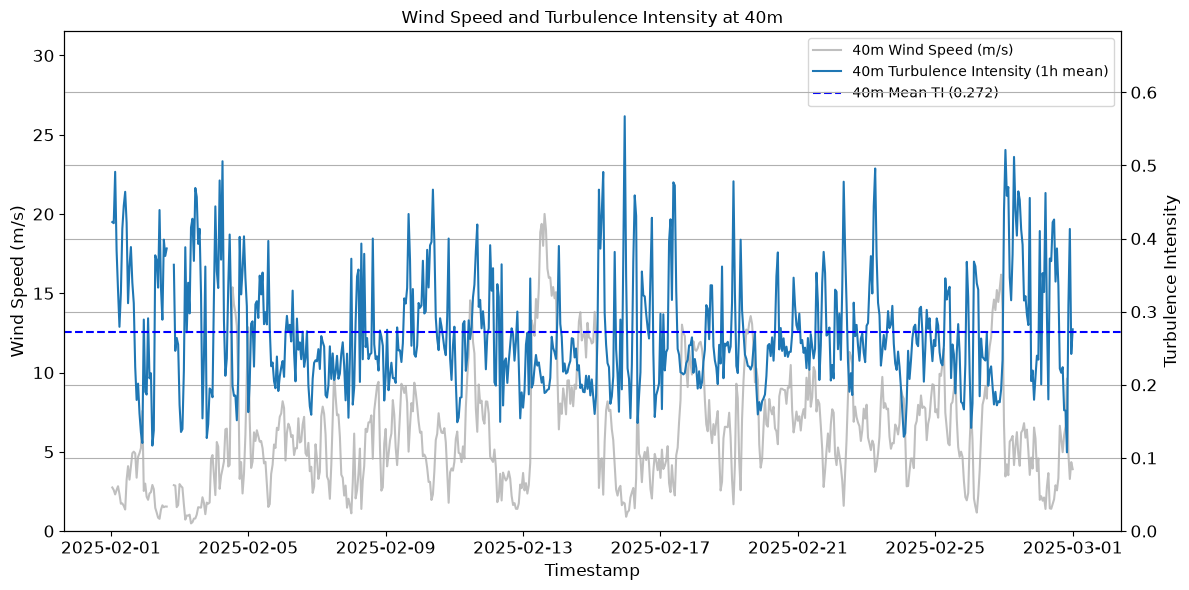

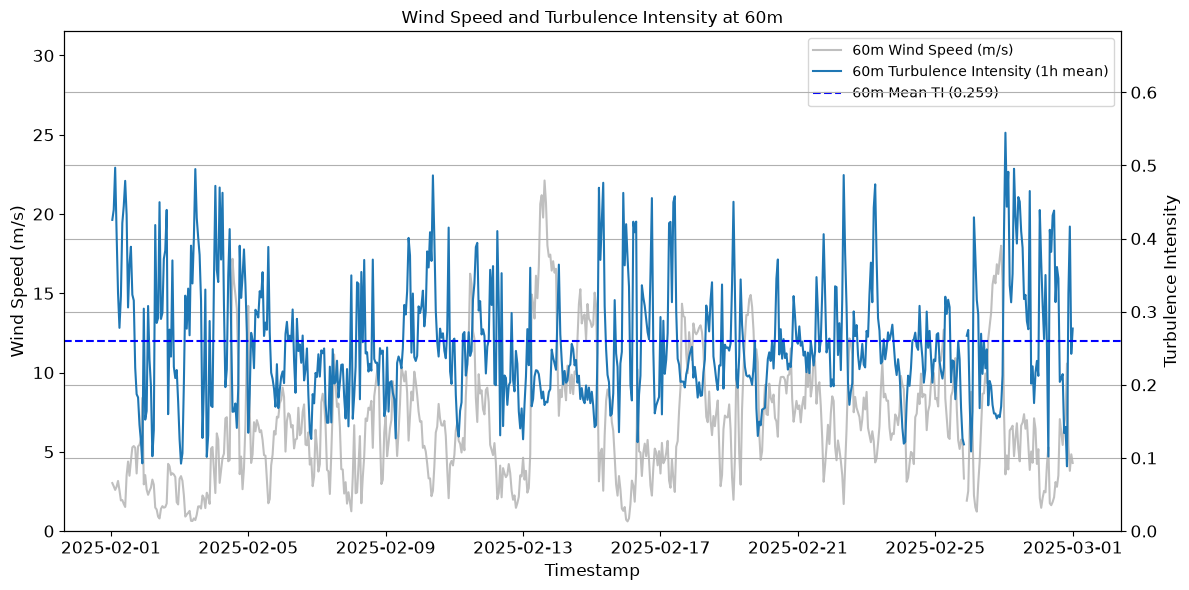

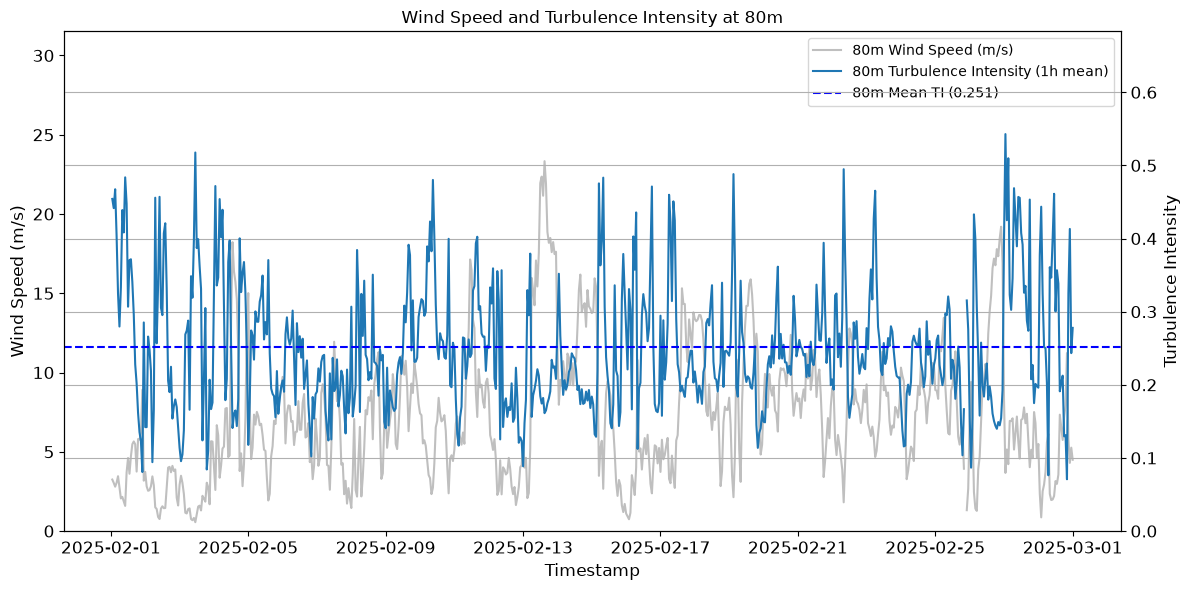

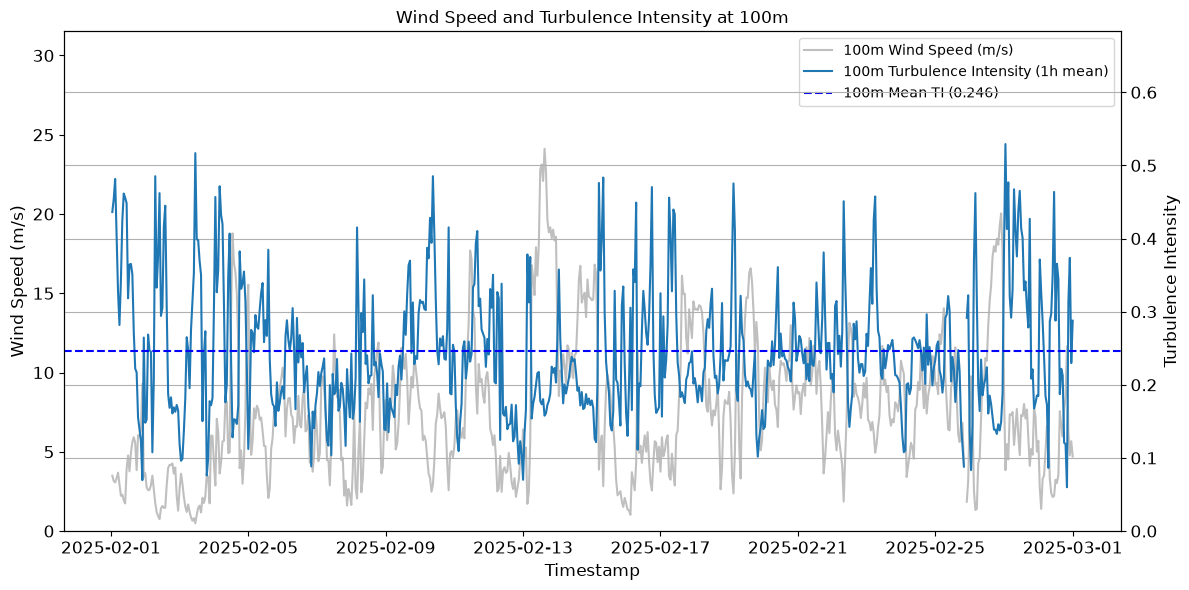

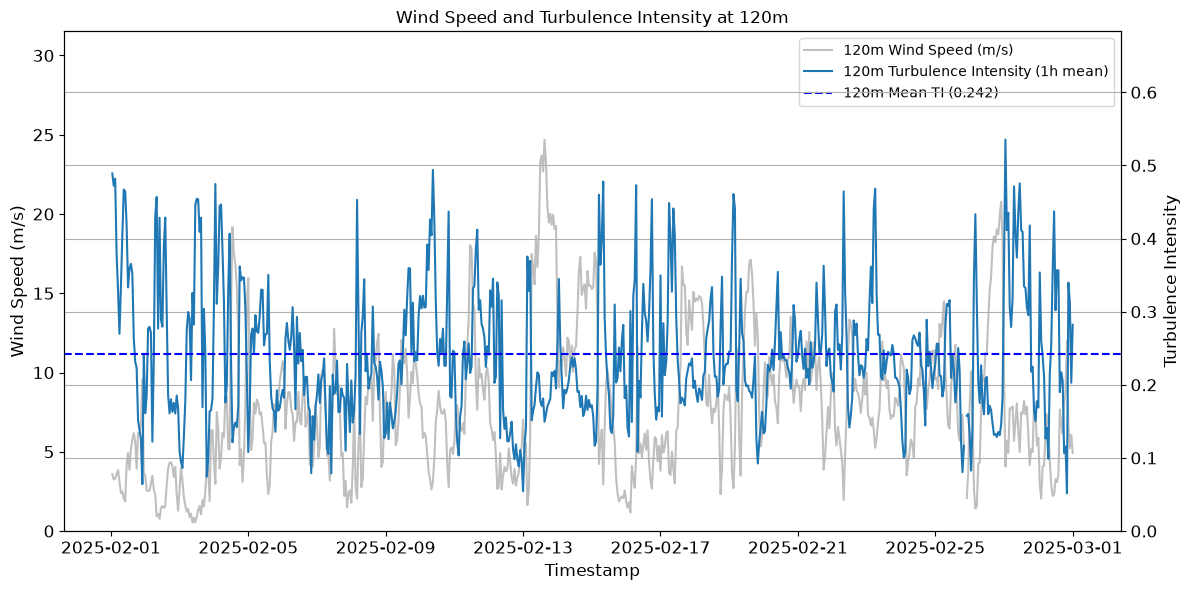

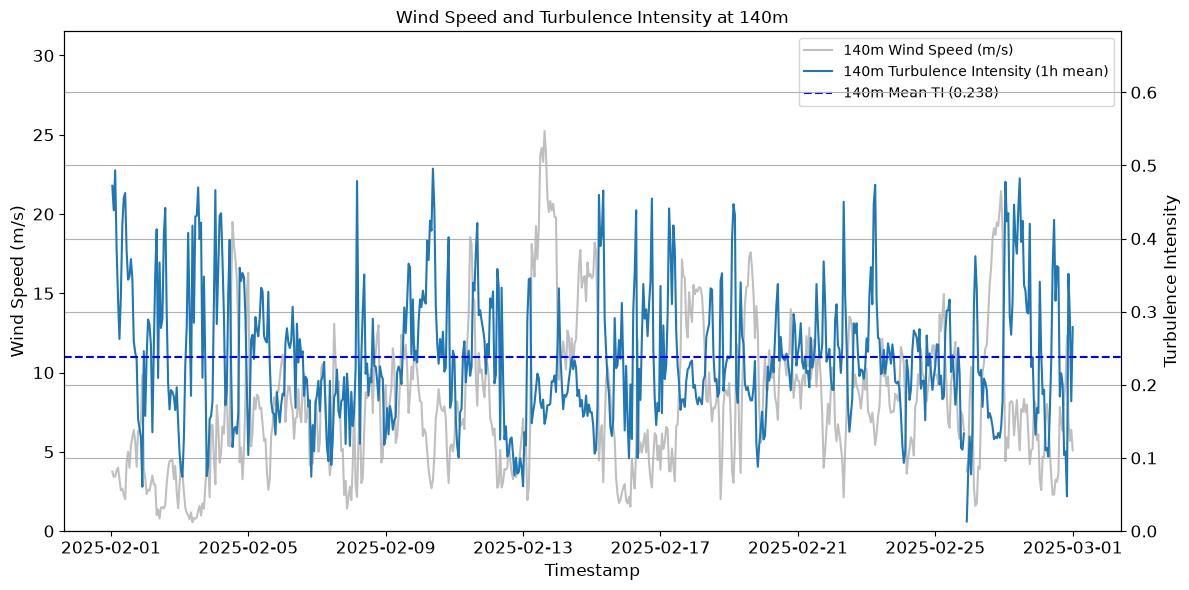

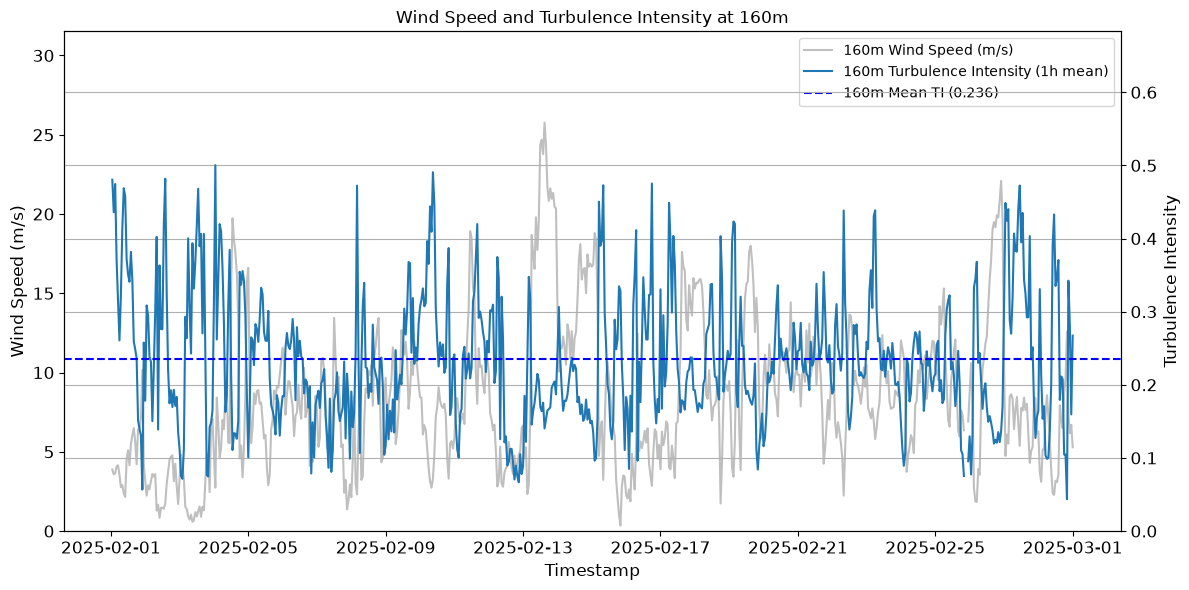

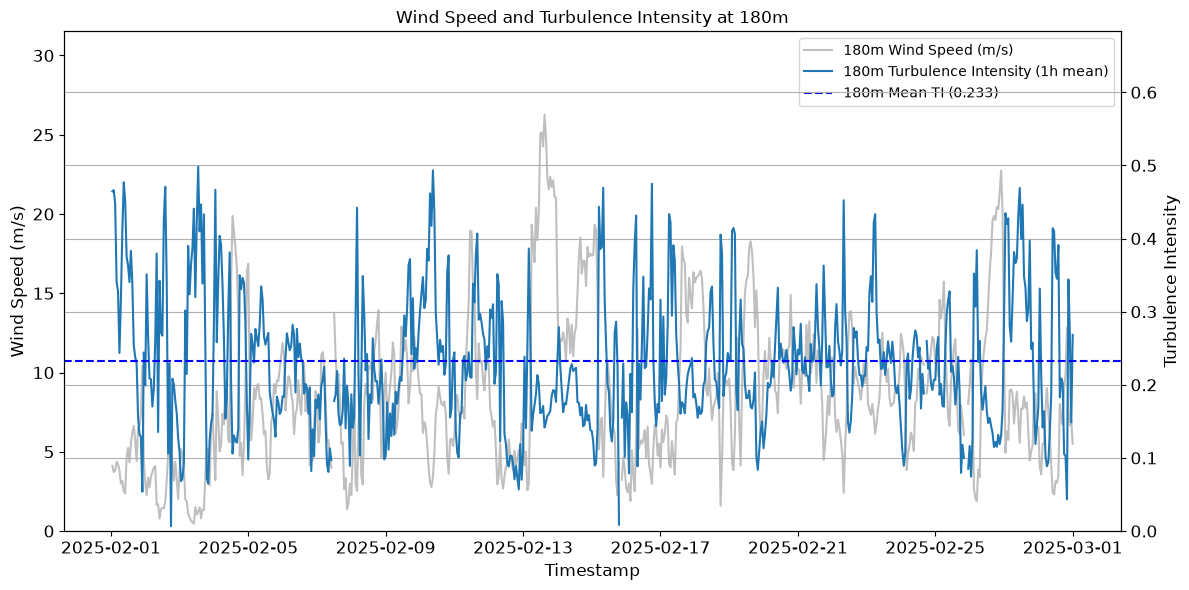

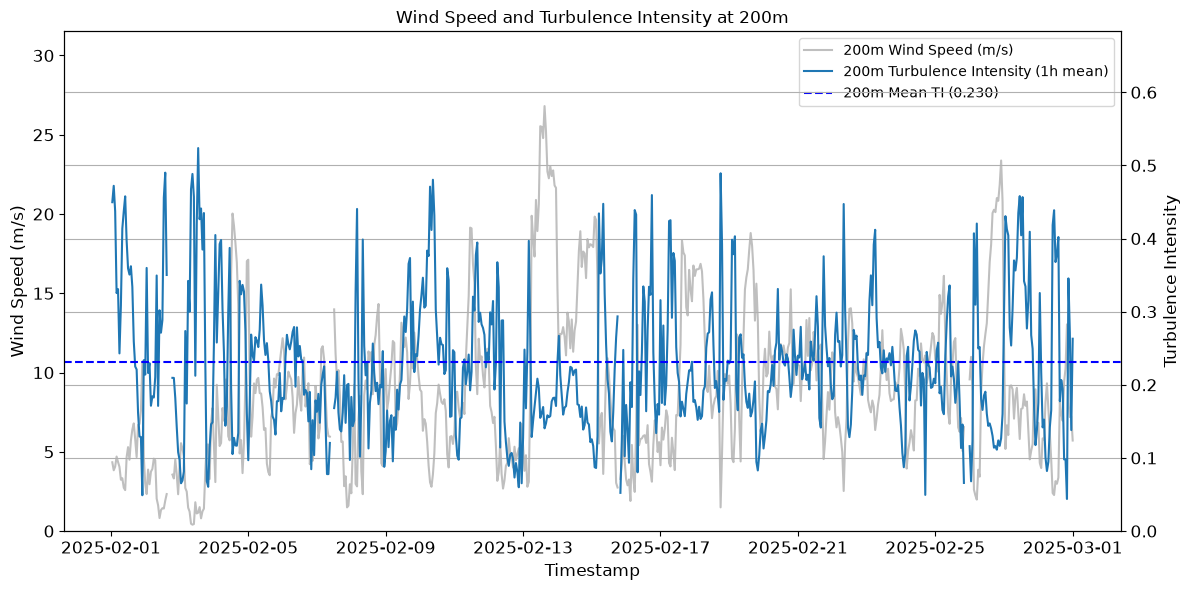

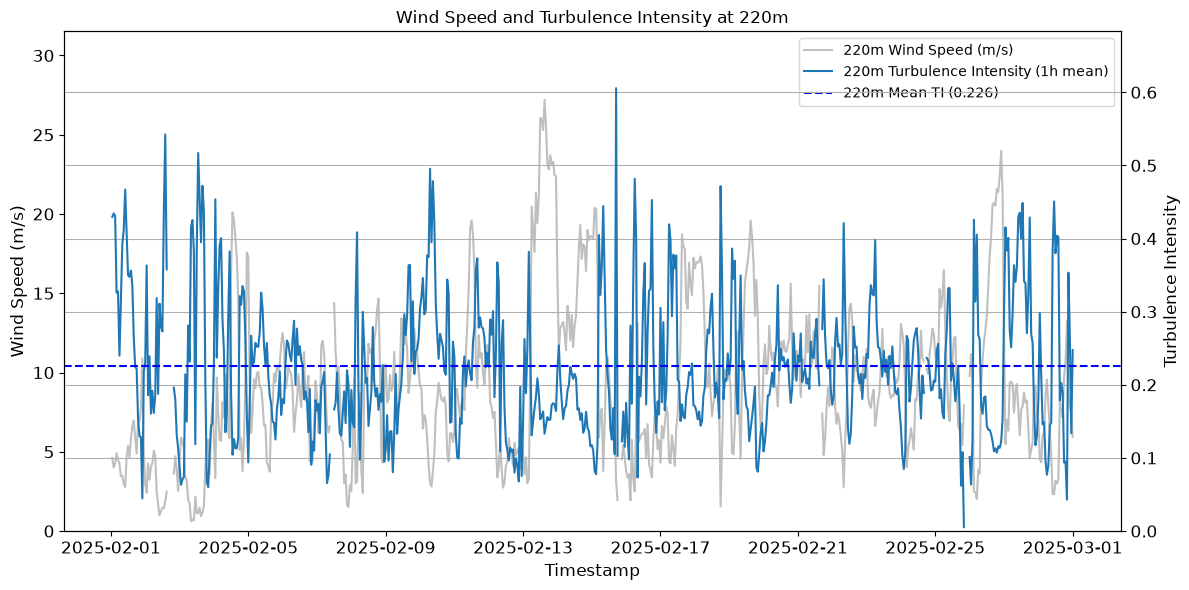

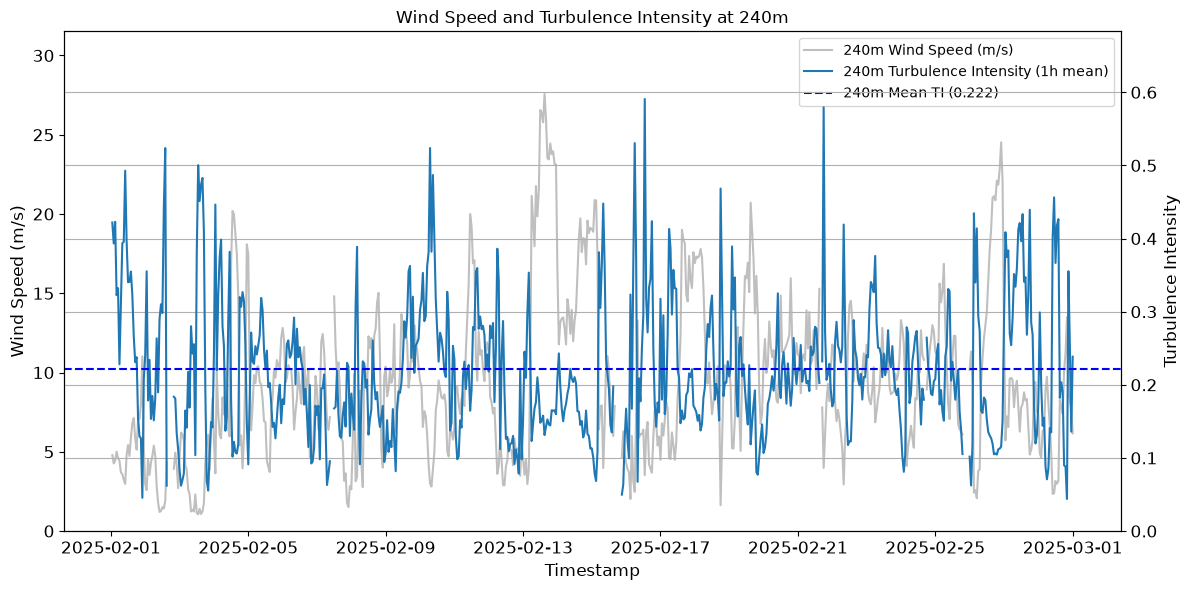

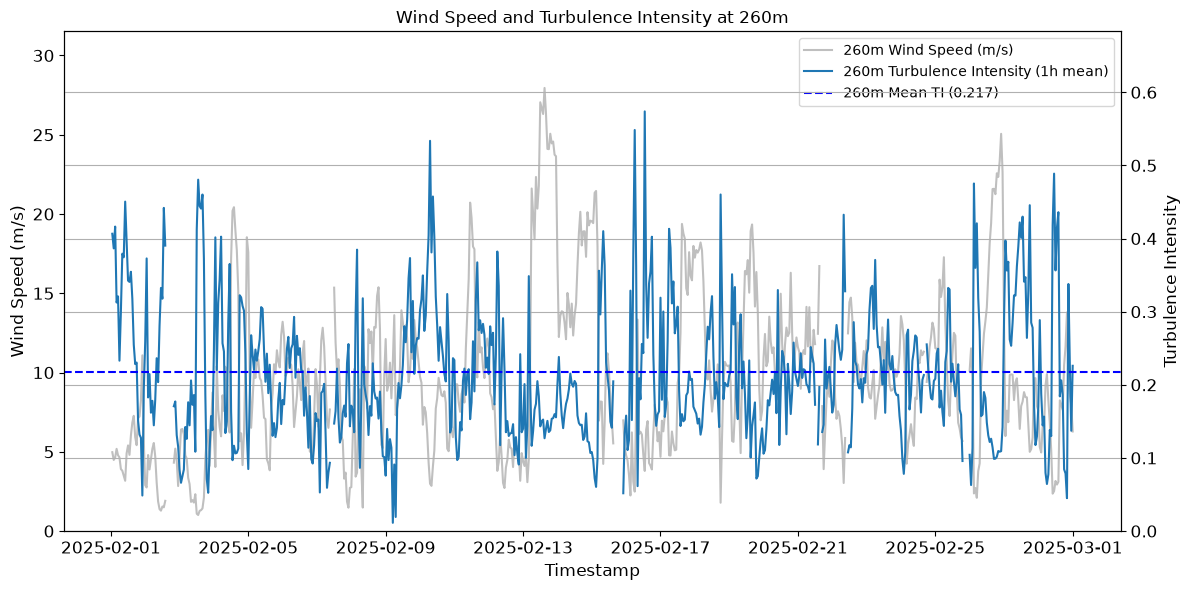

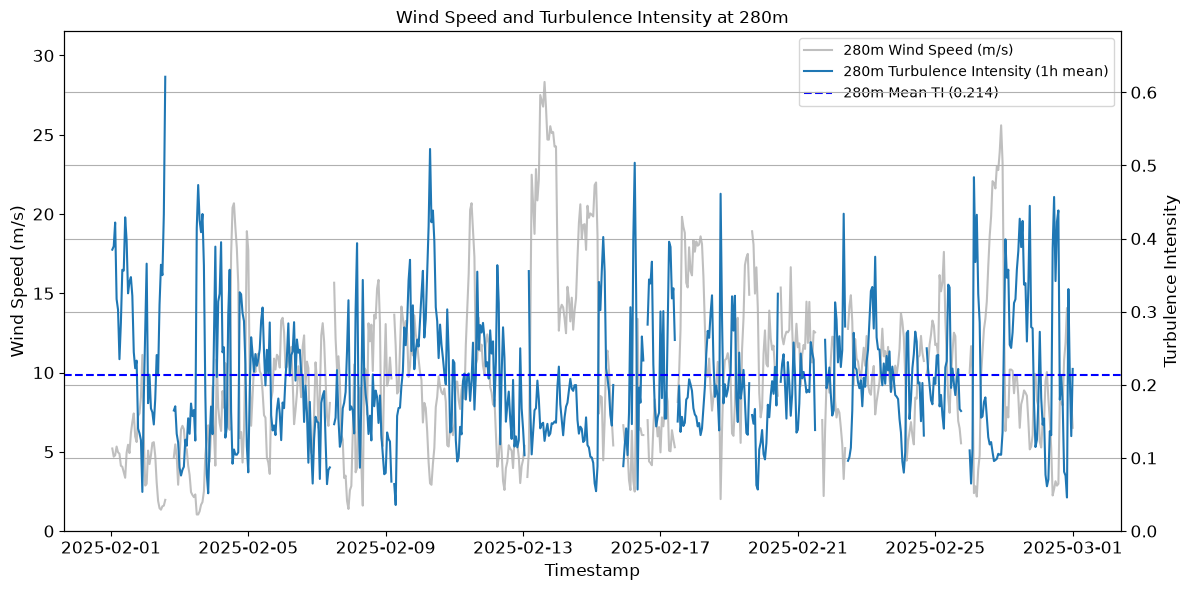

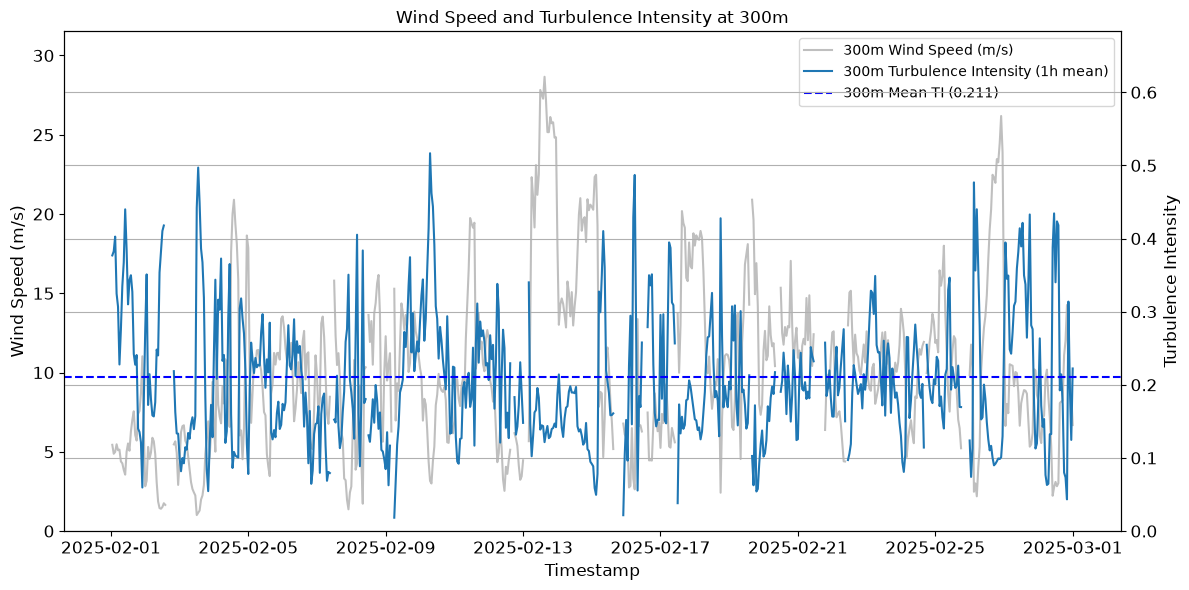

In [4]:
# プロット用に1時間平均を計算
df_TI_1h = df_TI.set_index('Timestamp').resample('1h', label='right', closed='right').mean().reset_index()

# 全高度における1時間平均データの最大値を取得
max_u = df_TI_1h[[f"{h}m_U" for h in heights]].max().max()
max_ti = df_TI_1h[[f"{h}m_TI" for h in heights]].max().max()

for h in heights:
    fig, ax1 = plt.subplots(figsize=(12, 6))
    ax2 = ax1.twinx()

    # 左軸: 風速 U (1時間平均)
    line1 = ax1.plot(df_TI_1h['Timestamp'], df_TI_1h[f"{h}m_U"], label=f"{h}m Wind Speed (m/s)", color='gray', alpha=0.5)
    ax1.set_xlabel("Timestamp", fontsize=12)
    ax1.set_ylabel("Wind Speed (m/s)", color='black', fontsize=12)
    ax1.set_ylim(0, max_u * 1.1)
    ax1.tick_params(labelsize=12)

    ax2.grid(True)

    # 右軸: 乱流強度 TI (1時間平均)
    line2 = ax2.plot(df_TI_1h['Timestamp'], df_TI_1h[f"{h}m_TI"], label=f"{h}m Turbulence Intensity (1h mean)", color='tab:blue', alpha=1.0)

    # 右軸: 期間全体のTI平均値
    mean_ti = df_TI[f"{h}m_TI"].mean()
    line3 = ax2.axhline(mean_ti, color='blue', alpha=1.0, linestyle='--', label=f"{h}m Mean TI ({mean_ti:.3f})")

    ax2.set_ylabel("Turbulence Intensity", fontsize=12)
    ax2.set_ylim(0, max_ti * 1.1)
    ax2.tick_params(labelsize=12)
    #ax2.tick_params(axis='y', labelcolor='tab:blue')

    # 凡例をまとめて表示
    lines = line1 + line2 + [line3]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper right')

    plt.title(f"Wind Speed and Turbulence Intensity at {h}m", fontsize=12)
    plt.tight_layout()
    plt.show()

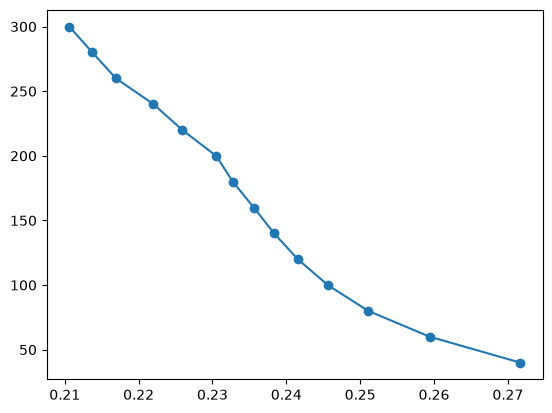

In [8]:
ti_values = []
for h in heights:
    ti_values.append(df_TI[f"{h}m_TI"].mean())
plt.plot( ti_values, heights,marker='o')

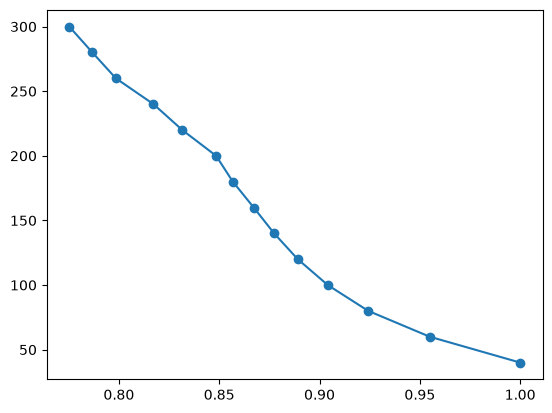

In [10]:
ti_values = []
for h in heights:
    ti_values.append(df_TI[f"{h}m_TI"].mean()/df_TI[f"40m_TI"].mean())
plt.plot( ti_values, heights,marker='o')